# Term Life Insurance – Net Premium Visualization

## Objective

This notebook investigates the relationship between the entry age $x$ of an insured person and the annual net premium $P$ of a term life insurance contract.

The analysis compares the resulting premiums for male and female policyholders.

## Methodology

The calculations are performed using the custom Python classes `MortalityTable` and `TermLifeInsurance`.

The net premium is determined according to the equivalence principle:

$$
EPV_{\text{Benefits}}(x) = EPV_{\text{Premiums}}(x)
$$

with

$$
EPV_{\text{Benefits}}(x) = C \cdot \sum\limits_{k=1}^{n} v^{k} \cdot {}_{k-1|}q_x
$$

and

$$
EPV_{\text{Premiums}}(x) = P \cdot \sum\limits_{k=0}^{n-1} v^{k} \cdot {}_{k}p_{x}
$$

where ${}_{k-1|}q_x$ is the probability that the individual dies with age $x+k-1$ and ${}_{k}p_{x}$ is the probability that the individual survives until age $x+k$ when being $x$ years old at the beginning of the contract.

## Model assumptions

- Fixed insurance term of $n=10$ years
- Constant interest rate of $i=3\%$ so $v=\frac{1}{1.03}$
- Death benefit of $C=100000$
- Annual premiums $P$ are due at the start of each year (in advance)
- Death benefit is paid in the end of the year of death
- No expenses, commissions or additional policyholder benefits

The mortality assumptions are based on the mortality data documented in `DATA_SOURCE.md`.

In [22]:
# Import libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mortality import MortalityTable
from products import TermLifeInsurance

In [23]:
# Load mortality data
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (PROJECT_ROOT / "data" / "processed" / "mortality_table.csv")

df = pd.read_csv(DATA_PATH)

mortality_table = MortalityTable(df)

In [24]:
# Create insurance
TERM = 10
INTEREST_RATE = 0.03
DEATH_BENEFIT = 100000

insurance = TermLifeInsurance(term=TERM, interest_rate=INTEREST_RATE, death_benefit=DEATH_BENEFIT, mortality_table=mortality_table)

In [25]:
# Restrict analysis to ages between 20 and 70
start_age = 20
end_age = 70

ages = np.arange(start_age, end_age + 1)

results = []

# Generate results
for age in ages:
    premium_male = insurance.net_premium(age=age, gender="male")
    premium_female = insurance.net_premium(age=age, gender="female")
    results.append({
        "age": age,
        "premium_male": premium_male,
        "premium_female": premium_female})

results_df = pd.DataFrame(results)
results_df.head()

,age,premium_male,premium_female
0,20,44.434416,19.333181
1,21,44.890191,19.822770
2,22,45.862468,20.518163
3,23,47.020325,21.798390
4,24,48.938583,23.322143


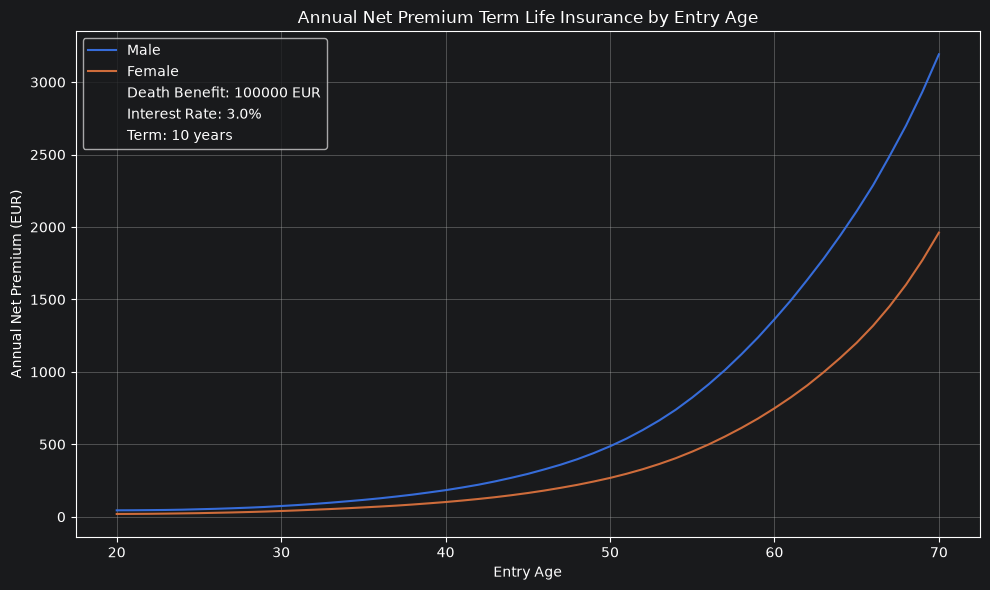

In [26]:
# Visualize results
plt.figure(figsize=(10, 6))

plt.plot(results_df["age"], results_df["premium_male"], label="Male")

plt.plot(results_df["age"], results_df["premium_female"], label="Female")

plt.title("Annual Net Premium Term Life Insurance by Entry Age")

plt.xlabel("Entry Age")
plt.ylabel("Annual Net Premium (EUR)")

# Create invisible lines to display parameters in legend
plt.axhline(y=0, color='none', label=f"Death Benefit: {DEATH_BENEFIT} EUR")
plt.axhline(y=0, color='none', label=f"Interest Rate: {INTEREST_RATE * 100}%")
plt.axhline(y=0, color='none', label=f"Term: {TERM} years")

plt.legend()
plt.grid(True)

plt.tight_layout()

# safe figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "net_premium_TLI_by_age.png")
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")

plt.show()